# 02. Modelagem não supervisionada das denúncias do Disque 100

A unidade de análise é a **denúncia única (`hash`)**. O notebook consome a base agregada criada no Notebook 01, impedindo que denúncias com múltiplas linhas ou violações tenham peso artificialmente maior.


## 1. Configuração e carga


In [22]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.experimental import enable_iterative_imputer  # Required to enable IterativeImputer
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.ensemble import IsolationForest
from sklearn.metrics import silhouette_score,davies_bouldin_score,calinski_harabasz_score,adjusted_rand_score

warnings.filterwarnings("ignore")
RANDOM_STATE=42
DATA_FILE=Path("results/disque100_denuncias_modelagem.parquet")
VIOL_FILE=Path("results/matriz_violacoes_por_denuncia.parquet")
OUTPUT_DIR=Path("results/modelagem")
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)

df=pd.read_parquet(DATA_FILE)
assert df["hash"].is_unique,"A base de modelagem deve ter um registro por hash."
print(df.shape); df.head()


(1263, 150)


,hash,data_de_cadastro,sl_quantidade_vitimas,canal_de_atendimento,denuncia_emergencial,denunciante,cenario_da_violacao,pais,uf,municipio,...,violacao__LIBERDADE>SEXUAL>VIOLENCIA SEXUAL MEDIANTE FRAUDE,violacao__SEGURANCA>PSIQUICA,violacao__VIDA>ABORTO,violacao__VIDA>HOMICIDIO,violacao__VIDA>INCITACAO AO SUICIDIO,violacao__VIDA>SUICIDIO,violacao__VIOLENCIA INSTITUCIONAL,violacao__VIOLENCIA INSTITUCIONAL>EM RAZAO DE SER POLICIAL/MILITAR/DEMAIS AGENTE DE SEGURANCA PUBLICA,qtd_tipos_violacao,multiplas_violacoes
0,002F819E35D44A499A7A94986A57219BF5D730B561452B...,2024-08-09 21:40:20,1,WHATSAPP,NAO,A PROPRIA VITIMA,OUTROS,BR | BRASIL,DENUNCIANTE NAO SOUBE INFORMAR,DENUNCIANTE NAO SOUBE INFORMAR,...,0,0,0,0,0,0,0,0,5,1
1,00319EA24D89AC6035B7BE828079576473D1BB2F233C78...,2025-09-29 17:22:35,2,TELEFONICO,NAO,TERCEIRO,CASA DE FAMILIARES,BR | BRASIL,GO,5208707 | GOIANIA,...,0,0,0,0,0,0,0,0,1,0
2,005929E4587AF2DA96A76E5590A542467A1E397D0FAAEE...,2023-03-18 19:22:56,1,TELEFONICO,NAO,TERCEIRO,CASA DO SUSPEITO,BR | BRASIL,SP,353060 | MOGI DAS CRUZES,...,0,0,0,0,0,0,0,0,7,1
3,0062DF297FE1A0C845F3AC8DCFB177903DA85F777C1AAD...,2022-08-22 22:22:00,1,TELEFONICO,NAO,TERCEIRO,AMBIENTE VIRTUAL (NO AMBITO DA INTERNET),BR | BRASIL,MG,316292 | SAO JOAQUIM DE BICAS,...,0,0,0,0,0,0,0,0,2,1
4,007E8ED8E6552B24B9A9B3A33E86D98FB1F9F9BE049F8C...,2025-04-28 12:11:05,1,TELEFONICO,NAO,TERCEIRO,CASA ONDE RESIDE A VITIMA E O SUSPEITO,BR | BRASIL,SC,4215000 | RIO NEGRINHO,...,0,0,0,0,0,0,0,0,5,1


## 2. Features derivadas


In [23]:
df["data_de_cadastro"]=pd.to_datetime(df["data_de_cadastro"],errors="coerce")
df["ano_cadastro"]=df["data_de_cadastro"].dt.year
df["mes_cadastro"]=df["data_de_cadastro"].dt.month
df["trimestre_cadastro"]=df["data_de_cadastro"].dt.quarter
df["dia_semana_cadastro"]=df["data_de_cadastro"].dt.dayofweek
df["fim_de_semana"]=(df["dia_semana_cadastro"]>=5).astype("int8")

MAPA_REGIAO={"AC":"NORTE","AP":"NORTE","AM":"NORTE","PA":"NORTE","RO":"NORTE","RR":"NORTE","TO":"NORTE","AL":"NORDESTE","BA":"NORDESTE","CE":"NORDESTE","MA":"NORDESTE","PB":"NORDESTE","PE":"NORDESTE","PI":"NORDESTE","RN":"NORDESTE","SE":"NORDESTE","DF":"CENTRO-OESTE","GO":"CENTRO-OESTE","MT":"CENTRO-OESTE","MS":"CENTRO-OESTE","ES":"SUDESTE","MG":"SUDESTE","RJ":"SUDESTE","SP":"SUDESTE","PR":"SUL","RS":"SUL","SC":"SUL"}
for origem,destino in [("uf","regiao_ocorrencia"),("uf_da_vitima","regiao_vitima"),("uf_do_suspeito","regiao_suspeito")]:
    if origem in df: df[destino]=df[origem].map(MAPA_REGIAO)


## 3. Seleção das variáveis

**Excluídas:** identificador, data bruta, localidades de alta cardinalidade, campos textuais específicos e variáveis removidas por alta ausência no Notebook 01.

**Incluídas:** contexto da denúncia, perfis resumidos da vítima e do suspeito, tempo, região, quantidade de vítimas e indicadores binários de violações.


In [24]:
EXCLUIR={"hash","data_de_cadastro","municipio","municipio_da_vitima","sl_suspeito_municipio","profissao_da_vitima","profissao_do_suspeito","motivacao","vitima_especificacao_etnia","suspeito_especificacao_etnia"}
CANDIDATAS=[
"canal_de_atendimento","denuncia_emergencial","denunciante","cenario_da_violacao","pais","uf","frequencia","inicio_das_violacoes","sl_quantidade_vitimas","grupo_vulneravel","relacao_vitima_suspeito","genero_da_vitima","orientacao_sexual_da_vitima","faixa_etaria_da_vitima","nacionalidade_da_vitima","deficiencia_da_vitima","doenca_rara_da_vitima","vitima_preso_a","pais_da_vitima","uf_da_vitima","grau_de_instrucao_da_vitima","raca_cor_da_vitima","natureza_juridica_do_suspeito","genero_do_suspeito","orientacao_sexual_do_suspeito","faixa_etaria_do_suspeito","suspeito_nacionalidade","deficiencia_do_suspeito","doenca_rara_do_suspeito","suspeito_preso","pais_do_suspeito","uf_do_suspeito","grau_de_instrucao_do_suspeito","raca_cor_do_suspeito","sl_suspeito_ramo","ano_cadastro","mes_cadastro","trimestre_cadastro","dia_semana_cadastro","fim_de_semana","regiao_ocorrencia","regiao_vitima","regiao_suspeito","qtd_tipos_violacao","multiplas_violacoes"]
VIOL_COLS=[c for c in df.columns if c.startswith("violacao__")]
FEATURES=[c for c in CANDIDATAS+VIOL_COLS if c in df.columns and c not in EXCLUIR]
X=df[FEATURES].copy()
num_cols=X.select_dtypes(include=["number","bool"]).columns.tolist()
cat_cols=[c for c in X.columns if c not in num_cols]
print({"features":len(FEATURES),"numericas":len(num_cols),"categoricas":len(cat_cols),"violacoes":len(VIOL_COLS)})


{'features': 143, 'numericas': 108, 'categoricas': 35, 'violacoes': 100}


In [29]:
df.dtypes

hash                                                                                                                str
data_de_cadastro                                                                                         datetime64[ns]
sl_quantidade_vitimas                                                                                             Int64
canal_de_atendimento                                                                                                str
denuncia_emergencial                                                                                                str
                                                                                                              ...      
violacao__VIOLENCIA INSTITUCIONAL                                                                                  int8
violacao__VIOLENCIA INSTITUCIONAL>EM RAZAO DE SER POLICIAL/MILITAR/DEMAIS AGENTE DE SEGURANCA PUBLICA              int8
qtd_tipos_violacao                      

## 4. Pré-processamento


In [31]:
numeric_pipe=Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",RobustScaler())])
# categorical_pipe=Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),("onehot",OneHotEncoder(handle_unknown="ignore",min_frequency=0.01,sparse_output=True))])
categorical_pipe=Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="NÃO INFORMADO")),("onehot",OneHotEncoder(handle_unknown="ignore",min_frequency=0.01,sparse_output=True))])
preprocessor=ColumnTransformer([("num",numeric_pipe,num_cols),("cat",categorical_pipe,cat_cols)],sparse_threshold=1.0,verbose_feature_names_out=False)
X_pre=preprocessor.fit_transform(X)
feature_names=preprocessor.get_feature_names_out()
selector=VarianceThreshold(0.0)
X_sel=selector.fit_transform(X_pre)
selected_names=feature_names[selector.get_support()]
print("Matriz processada:",X_sel.shape)


Matriz processada: (1263, 376)


## 5. Redução de dimensionalidade

Como o one-hot gera matriz esparsa, usa-se `TruncatedSVD`. Os componentes são usados na clusterização para reduzir ruído e custo computacional.


{'componentes_disponiveis': 50, 'componentes_80pct': 10, 'usados': 10, 'variancia_acumulada': np.float64(0.804)}


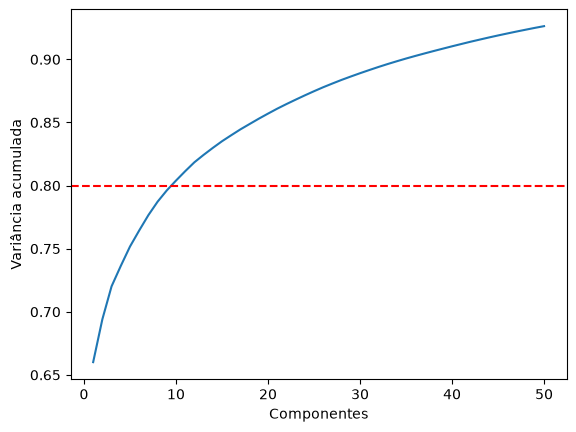

In [32]:
max_components=min(50,X_sel.shape[1]-1,X_sel.shape[0]-1)
svd=TruncatedSVD(n_components=max_components,random_state=RANDOM_STATE)
X_svd=svd.fit_transform(X_sel)
acum=np.cumsum(svd.explained_variance_ratio_)
n80=int(np.searchsorted(acum,0.80)+1)
n_model=max(2,min(n80,max_components))
X_model=X_svd[:,:n_model]
print({"componentes_disponiveis":max_components,"componentes_80pct":n80,"usados":n_model,"variancia_acumulada":round(acum[n_model-1],3)})
plt.plot(range(1,len(acum)+1),acum); plt.axhline(.80,color="red",ls="--"); plt.xlabel("Componentes"); plt.ylabel("Variância acumulada"); plt.show()


## 6. Clusterização K-Means


In [33]:
resultados=[]
for k in range(2,11):
    model=KMeans(n_clusters=k,n_init=30,random_state=RANDOM_STATE)
    labels=model.fit_predict(X_model)
    resultados.append({"algoritmo":"KMeans","k":k,"silhouette":silhouette_score(X_model,labels),"davies_bouldin":davies_bouldin_score(X_model,labels),"calinski_harabasz":calinski_harabasz_score(X_model,labels),"inercia":model.inertia_})
aval_k=pd.DataFrame(resultados)
display(aval_k)
BEST_K=int(aval_k.sort_values(["silhouette","davies_bouldin"],ascending=[False,True]).iloc[0]["k"])
kmeans=KMeans(n_clusters=BEST_K,n_init=50,random_state=RANDOM_STATE)
df["cluster_kmeans"]=kmeans.fit_predict(X_model)
print("BEST_K:",BEST_K); display(df["cluster_kmeans"].value_counts().sort_index())


,algoritmo,k,silhouette,davies_bouldin,calinski_harabasz,inercia
0,KMeans,2,0.797639,0.576067,1760.537254,34697.156513
1,KMeans,3,0.679957,0.509695,2513.747196,16660.947126
2,KMeans,4,0.627425,0.424693,2455.621156,12134.723979
3,KMeans,5,0.338390,0.926008,2232.277455,10266.830802
4,KMeans,6,0.240805,1.215084,2009.984799,9242.691829
5,KMeans,7,0.245754,1.077905,1869.750552,8370.918786
6,KMeans,8,0.254391,1.065264,1791.621838,7563.001009
7,KMeans,9,0.280243,1.038547,1760.089914,6798.740379
8,KMeans,10,0.284013,1.041725,1693.642323,6315.215935


BEST_K: 2


cluster_kmeans
0    1203
1      60
Name: count, dtype: int64

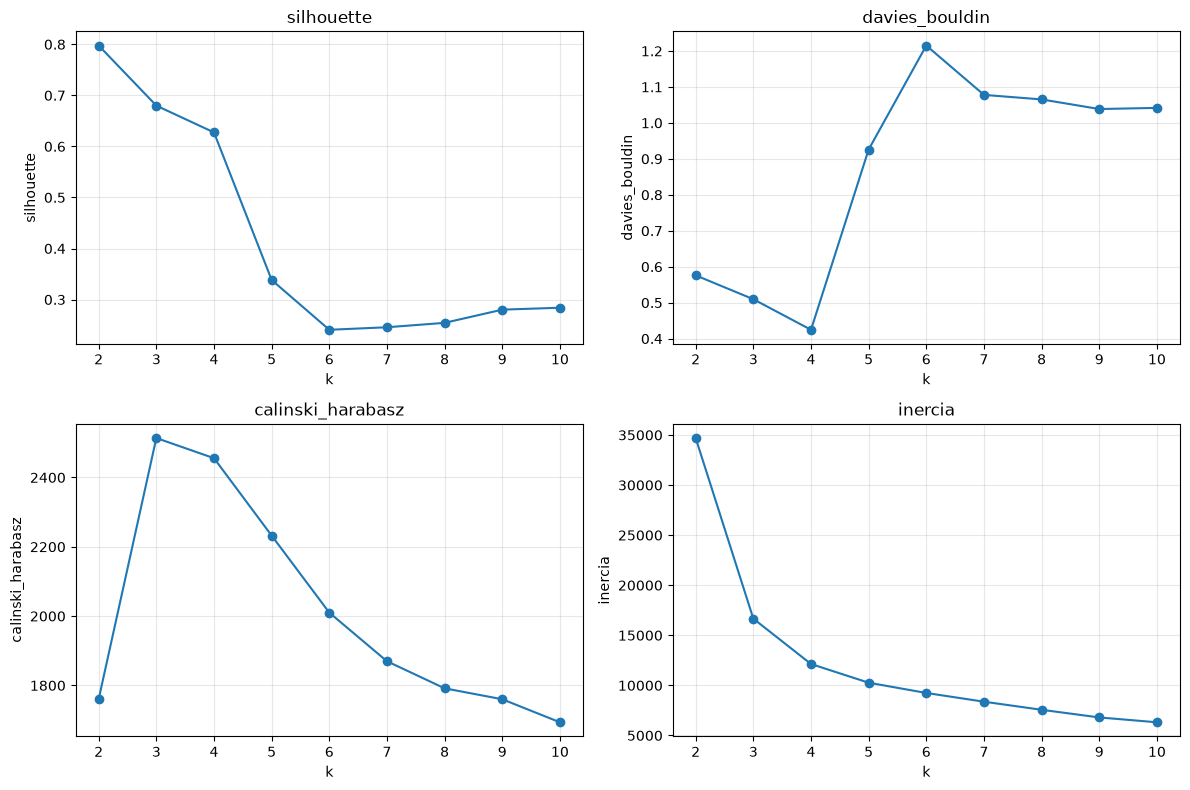

In [34]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, metrica in zip(axes.flat, ["silhouette", "davies_bouldin", "calinski_harabasz", "inercia"]):
    ax.plot(aval_k["k"], aval_k[metrica], marker="o")
    ax.set_xlabel("k")
    ax.set_ylabel(metrica)
    ax.set_title(metrica)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [36]:
# Interpretação dos gráficos de avaliação do K-Means
_por_k = aval_k.sort_values("k").reset_index(drop=True)

_linha_sil = _por_k.loc[_por_k["silhouette"].idxmax()]
_linha_db = _por_k.loc[_por_k["davies_bouldin"].idxmin()]
_linha_ch = _por_k.loc[_por_k["calinski_harabasz"].idxmax()]

print("Silhouette — maior é melhor")
print(
    f"O melhor valor ocorre em k={int(_linha_sil['k'])} "
    f"(silhouette={_linha_sil['silhouette']:.3f}), indicando a melhor "
    "separação e coesão relativas entre os grupos testados."
)

print("\nDavies-Bouldin — menor é melhor")
print(
    f"O menor valor ocorre em k={int(_linha_db['k'])} "
    f"(Davies-Bouldin={_linha_db['davies_bouldin']:.3f}), favorecendo "
    "essa solução por apresentar clusters mais compactos e separados."
)

print("\nCalinski-Harabasz — maior é melhor")
print(
    f"O maior valor ocorre em k={int(_linha_ch['k'])} "
    f"(Calinski-Harabasz={_linha_ch['calinski_harabasz']:.1f}), "
    "favorecendo essa quantidade de clusters dentro dos valores testados."
)

# A inércia sempre tende a diminuir quando k aumenta; o importante é observar
# quando a redução passa a ser menor (o 'cotovelo').
_ganhos_inercia = _por_k["inercia"].to_numpy()[:-1] - _por_k["inercia"].to_numpy()[1:]
if len(_ganhos_inercia) > 1:
    _perda_de_ganho = _ganhos_inercia[:-1] - _ganhos_inercia[1:]
    _idx_cotovelo = int(np.argmax(_perda_de_ganho))
    _k_cotovelo = int(_por_k.loc[_idx_cotovelo + 1, "k"])
    print("\nInércia — menor é melhor, mas tende a cair com o aumento de k")
    print(
        f"A maior desaceleração na redução da inércia aparece perto de "
        f"k={_k_cotovelo}, sugerindo esse ponto como possível cotovelo. "
        "Use-o como referência visual, não como escolha automática."
    )
else:
    print("\nInércia: há poucos valores de k para estimar um possível cotovelo.")

print(
    "\nSíntese: os indicadores podem apontar para valores diferentes de k. "
    "Compare as soluções sugeridas e considere também o tamanho e a "
    "interpretabilidade dos clusters; nenhuma métrica, isoladamente, "
    "determina a quantidade correta."
)

Silhouette — maior é melhor
O melhor valor ocorre em k=2 (silhouette=0.798), indicando a melhor separação e coesão relativas entre os grupos testados.

Davies-Bouldin — menor é melhor
O menor valor ocorre em k=4 (Davies-Bouldin=0.425), favorecendo essa solução por apresentar clusters mais compactos e separados.

Calinski-Harabasz — maior é melhor
O maior valor ocorre em k=3 (Calinski-Harabasz=2513.7), favorecendo essa quantidade de clusters dentro dos valores testados.

Inércia — menor é melhor, mas tende a cair com o aumento de k
A maior desaceleração na redução da inércia aparece perto de k=3, sugerindo esse ponto como possível cotovelo. Use-o como referência visual, não como escolha automática.

Síntese: os indicadores podem apontar para valores diferentes de k. Compare as soluções sugeridas e considere também o tamanho e a interpretabilidade dos clusters; nenhuma métrica, isoladamente, determina a quantidade correta.


## 7. Clusterização hierárquica e baseada em densidade


In [37]:
hier=AgglomerativeClustering(n_clusters=BEST_K,linkage="ward")
df["cluster_hierarquico"]=hier.fit_predict(X_model)

dbscan=DBSCAN(eps=1.0,min_samples=max(5,int(np.sqrt(len(df)))))
df["cluster_dbscan"]=dbscan.fit_predict(X_model)
print(df["cluster_dbscan"].value_counts().sort_index())


cluster_dbscan
-1    1263
Name: count, dtype: int64


## 8. Avaliação interna e estabilidade


In [ ]:
avaliacoes=[]
for nome,col in [("KMeans","cluster_kmeans"),("Hierarquico-Ward","cluster_hierarquico")]:
    lab=df[col].to_numpy()
    avaliacoes.append({"algoritmo":nome,"silhouette":silhouette_score(X_model,lab),"davies_bouldin":davies_bouldin_score(X_model,lab),"calinski_harabasz":calinski_harabasz_score(X_model,lab)})
avaliacoes=pd.DataFrame(avaliacoes)
display(avaliacoes)

ref=df["cluster_kmeans"].to_numpy(); estabilidade=[]
for seed in range(20):
    lab=KMeans(n_clusters=BEST_K,n_init=20,random_state=seed).fit_predict(X_model)
    estabilidade.append({"seed":seed,"adjusted_rand":adjusted_rand_score(ref,lab)})
estabilidade=pd.DataFrame(estabilidade)
display(estabilidade.describe())


,algoritmo,silhouette,davies_bouldin,calinski_harabasz
0,KMeans,0.819889,0.559147,1959.233131
1,Hierarquico-Ward,0.884200,0.188899,1511.591299


,seed,adjusted_rand
count,20.00000,20.0
mean,9.50000,1.0
std,5.91608,0.0
min,0.00000,1.0
25%,4.75000,1.0
50%,9.50000,1.0
75%,14.25000,1.0
max,19.00000,1.0


## 9. Associação entre violações


In [39]:
matriz=pd.read_parquet(VIOL_FILE).set_index("hash").astype(bool)
# requer: pip install mlxtend
try:
    from mlxtend.frequent_patterns import apriori, association_rules
    itemsets=apriori(matriz,min_support=0.01,use_colnames=True,max_len=4)
    regras=association_rules(itemsets,metric="lift",min_threshold=1.0)
    regras=regras.query("confidence >= 0.20").sort_values(["lift","confidence","support"],ascending=False)
    display(regras[["antecedents","consequents","support","confidence","lift"]].head(50))
except ImportError:
    regras=pd.DataFrame()
    print("Instale mlxtend para executar Apriori: pip install mlxtend")


,antecedents,consequents,support,confidence,lift
55114,frozenset({INTEGRIDADE>PSIQUICA>EXPOSICAO (ERO...,frozenset({LIBERDADE>DIREITOS INDIVIDUAIS>COND...,0.010293,0.928571,90.214286
55128,frozenset({LIBERDADE>DIREITOS INDIVIDUAIS>COND...,frozenset({LIBERDADE>DIREITOS INDIVIDUAIS>COND...,0.010293,0.928571,90.214286
56598,"frozenset({LIBERDADE>SEXUAL>FISICA>ESTUPRO, LI...",frozenset({LIBERDADE>DIREITOS INDIVIDUAIS>COND...,0.010293,0.928571,90.214286
16389,"frozenset({VIOLENCIA INSTITUCIONAL, DIREITOS S...","frozenset({INTEGRIDADE>NEGLIGENCIA, DIREITOS S...",0.011085,1.000000,90.214286
16392,"frozenset({INTEGRIDADE>NEGLIGENCIA, DIREITOS S...","frozenset({VIOLENCIA INSTITUCIONAL, DIREITOS S...",0.011085,1.000000,90.214286
16403,frozenset({VIOLENCIA INSTITUCIONAL>EM RAZAO DE...,"frozenset({INTEGRIDADE>NEGLIGENCIA, DIREITOS S...",0.011085,1.000000,90.214286
16406,"frozenset({INTEGRIDADE>NEGLIGENCIA, DIREITOS S...",frozenset({VIOLENCIA INSTITUCIONAL>EM RAZAO DE...,0.011085,1.000000,90.214286
16543,frozenset({VIOLENCIA INSTITUCIONAL>EM RAZAO DE...,"frozenset({VIOLENCIA INSTITUCIONAL, DIREITOS S...",0.011085,1.000000,90.214286
16544,frozenset({VIOLENCIA INSTITUCIONAL>EM RAZAO DE...,"frozenset({VIOLENCIA INSTITUCIONAL, DIREITOS S...",0.011085,1.000000,90.214286
16545,"frozenset({VIOLENCIA INSTITUCIONAL, DIREITOS S...",frozenset({VIOLENCIA INSTITUCIONAL>EM RAZAO DE...,0.011085,1.000000,90.214286


## 10. Detecção de anomalias


In [40]:
iforest=IsolationForest(n_estimators=500,contamination="auto",random_state=RANDOM_STATE,n_jobs=-1)
df["anomalia_iforest"]=iforest.fit_predict(X_model)
df["score_anomalia_iforest"]=iforest.decision_function(X_model)
display(df.nsmallest(30,"score_anomalia_iforest")[["hash","score_anomalia_iforest","cluster_kmeans","qtd_tipos_violacao","sl_quantidade_vitimas"]])


,hash,score_anomalia_iforest,cluster_kmeans,qtd_tipos_violacao,sl_quantidade_vitimas
1214,F585BC8F7823850FB2B4CE43841D13D4,-0.203772,1,7,60
484,6362B17D072BE85A138C40989E645EC1,-0.200885,1,4,60
1254,FE98C48CE3636BE263DAB63E8B46EA49,-0.198938,1,4,60
834,A7CC34DD65611FDE2FA06C55FFA03B1B,-0.183637,1,1,60
1042,D1CECC9833E7D5CE2B80B76DDEDB9743,-0.182678,1,1,60
151,1C9EF0B20EACA2B2229CD832F1294E51,-0.182358,1,1,60
248,3371D75E9DE7FB813CA205CB8CF1CBED,-0.181750,1,1,60
965,C28C100F83EED50ECBD6834F046E0491,-0.181565,1,1,60
503,683D2FF7A261492C663BCD2297548EA1,-0.179202,1,1,60
1139,E66C22AE66EBF300A2F5C529001F0946,-0.161191,1,4,50


## 11. Interpretação dos clusters


In [41]:
# Tamanho
tamanho=df.groupby("cluster_kmeans").size().rename("n").to_frame()
tamanho["pct"]=(tamanho["n"]/len(df)*100).round(2)
display(tamanho)

# Numéricas nas escalas originais
num_interpret=[c for c in ["sl_quantidade_vitimas","qtd_tipos_violacao","ano_cadastro","mes_cadastro"] if c in df]
display(df.groupby("cluster_kmeans")[num_interpret].median())

# Categoria modal e distribuição relativa
def moda(s):
    m=s.dropna().mode(); return m.iloc[0] if not m.empty else np.nan
cat_interpret=[c for c in ["cenario_da_violacao","frequencia","grupo_vulneravel","genero_da_vitima","faixa_etaria_da_vitima","raca_cor_da_vitima","genero_do_suspeito","faixa_etaria_do_suspeito","relacao_vitima_suspeito","regiao_ocorrencia"] if c in df]
display(df.groupby("cluster_kmeans")[cat_interpret].agg(moda))

# Violações mais características por cluster
viol_cols=[c for c in df.columns if c.startswith("violacao__")]
perfil_viol=df.groupby("cluster_kmeans")[viol_cols].mean().T
for cluster in perfil_viol.columns:
    display(perfil_viol[cluster].sort_values(ascending=False).head(15).to_frame(f"cluster_{cluster}"))


,n,pct
cluster_kmeans,,
0,1203,95.25
1,60,4.75


,sl_quantidade_vitimas,qtd_tipos_violacao,ano_cadastro,mes_cadastro
cluster_kmeans,,,,
0,1.0,5.0,2024.0,7.0
1,20.0,3.0,2021.0,5.0


,cenario_da_violacao,frequencia,grupo_vulneravel,genero_da_vitima,faixa_etaria_da_vitima,raca_cor_da_vitima,genero_do_suspeito,faixa_etaria_do_suspeito,relacao_vitima_suspeito,regiao_ocorrencia
cluster_kmeans,,,,,,,,,,
0,CASA ONDE RESIDE A VITIMA E O SUSPEITO,DIARIAMENTE,VIOLENCIA CONTRA CRIANCA OU ADOLESCENTE,FEMININO,CRIANCA/ADOLESCENTE IDADE NAO INFORMADA,BRANCA,FEMININO,30 A 34 ANOS,OUTROS,SUDESTE
1,CASA ONDE RESIDE A VITIMA E O SUSPEITO,DIARIAMENTE,VIOLENCIA CONTRA CRIANCA OU ADOLESCENTE,FEMININO,02 A 04 ANOS,N/D,FEMININO,N/D,OUTROS,SUDESTE


,cluster_0
violacao__LIBERDADE>DIREITOS INDIVIDUAIS>TRAFICO DE CRIANCAS - NACIONAL,0.412303
violacao__INTEGRIDADE>PSIQUICA>TORTURA PSIQUICA,0.406484
violacao__INTEGRIDADE>NEGLIGENCIA,0.385702
violacao__INTEGRIDADE>FISICA>EXPOSICAO DE RISCO A SAUDE,0.374896
violacao__LIBERDADE>SEXUAL>FISICA>EXPLORACAO SEXUAL,0.270989
violacao__LIBERDADE>DIREITOS INDIVIDUAIS>TRAFICO DE PESSOAS - NACIONAL,0.264339
violacao__LIBERDADE>DIREITOS INDIVIDUAIS>TRAFICO DE PESSOAS - INTERNACIONAL,0.257689
violacao__INTEGRIDADE>PSIQUICA>CONSTRANGIMENTO,0.253533
violacao__INTEGRIDADE>PSIQUICA>AMEACA OU COACAO,0.250208
violacao__INTEGRIDADE>FISICA>MAUS TRATOS,0.217789


,cluster_1
violacao__LIBERDADE>DIREITOS INDIVIDUAIS>TRAFICO DE PESSOAS - NACIONAL,0.683333
violacao__LIBERDADE>DIREITOS INDIVIDUAIS>TRAFICO DE PESSOAS - INTERNACIONAL,0.416667
violacao__INTEGRIDADE>PSIQUICA>AMEACA OU COACAO,0.216667
violacao__INTEGRIDADE>FISICA>EXPOSICAO DE RISCO A SAUDE,0.183333
violacao__INTEGRIDADE>FISICA>MAUS TRATOS,0.183333
violacao__INTEGRIDADE>PSIQUICA>EXPOSICAO,0.166667
violacao__INTEGRIDADE>PSIQUICA>TORTURA PSIQUICA,0.166667
violacao__INTEGRIDADE>PSIQUICA>INSUBSISTENCIA AFETIVA,0.150000
violacao__DIREITOS SOCIAIS>PROTECAO A INFANCIA,0.133333
violacao__LIBERDADE>DIREITOS INDIVIDUAIS>EXTORSAO MEDIANTE SEQUESTRO,0.116667


## 12. Visualização bidimensional


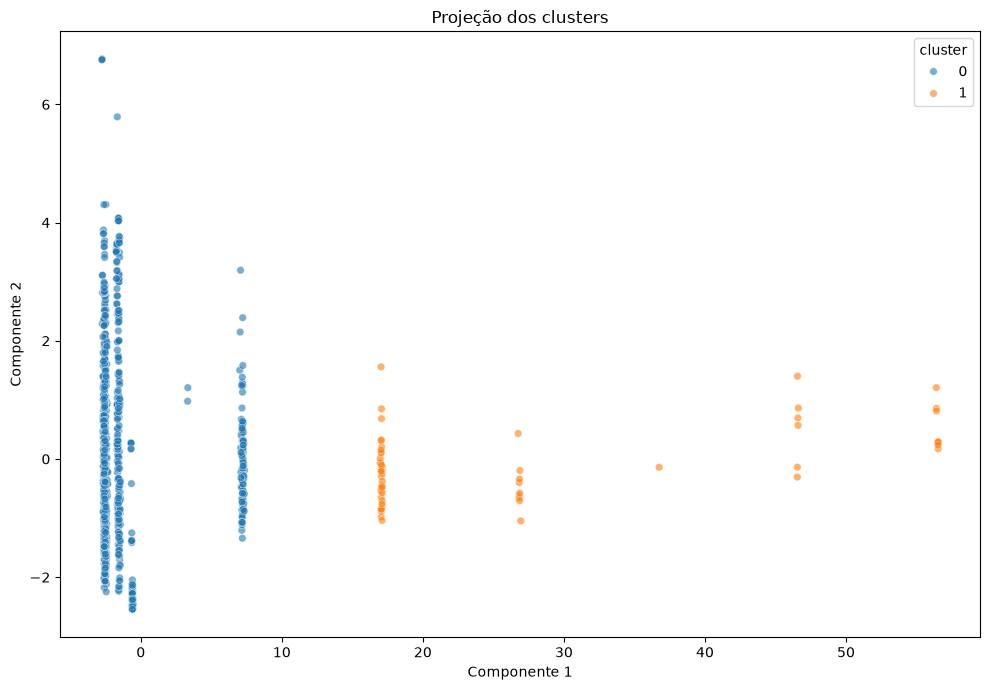

In [42]:
pca2=PCA(n_components=2,random_state=RANDOM_STATE)
coords=pca2.fit_transform(X_model)
plot_df=pd.DataFrame({"Componente 1":coords[:,0],"Componente 2":coords[:,1],"cluster":df["cluster_kmeans"].astype(str)})
plt.figure(figsize=(10,7)); sns.scatterplot(data=plot_df,x="Componente 1",y="Componente 2",hue="cluster",alpha=.6,s=30); plt.title("Projeção dos clusters"); plt.tight_layout(); plt.show()


## 13. Exportação


In [43]:
df.to_parquet(OUTPUT_DIR/"denuncias_com_clusters_e_anomalias.parquet",index=False)
avaliacoes.to_csv(OUTPUT_DIR/"avaliacao_modelos.csv",index=False,encoding="utf-8-sig")
estabilidade.to_csv(OUTPUT_DIR/"estabilidade_kmeans.csv",index=False,encoding="utf-8-sig")
tamanho.to_csv(OUTPUT_DIR/"tamanho_clusters.csv",encoding="utf-8-sig")
if not regras.empty: regras.to_csv(OUTPUT_DIR/"regras_associacao.csv",index=False,encoding="utf-8-sig")
print("Resultados em",OUTPUT_DIR.resolve())


Resultados em C:\Projetos\eda-disque100-completo\outros_notebooks_para_analisar\results\modelagem


## 14. Conclusões e cautelas

Registre os perfis encontrados, a estabilidade, as regras substantivamente relevantes e as anomalias que merecem inspeção. Evite interpretar clusters como categorias reais ou causais. Considere subnotificação, ausência não aleatória e mudanças administrativas no período.
